# 01. Statistical & Tabular Exploratory Data Analysis

**Dataset**: *Status of Springs in Seven Municipalities of Kavre, Nepal*
- **Source**: ICIMOD Regional Database System (DOI: `10.26066/RDS.1974131`)
- **Reference Paper**: Thapa et al. (2025), *Data in Brief*, 60, 111466
- **License**: Creative Commons Attribution 4.0 International (CC BY 4.0)
- **Sample Size**: 5,689 water sources surveyed across 7 local governments in Kavrepalanchok

This notebook provides the **statistical and tabular EDA** of the field survey before integrating spatial and satellite covariates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set high-DPI publication styling
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10
sns.set_theme(style='whitegrid')

# Load cleaned dataset
df = pd.read_csv('../data/processed/clean_springs.csv')
print(f"Loaded survey data: {df.shape[0]} rows, {df.shape[1]} columns")
df[['id', 'municipality', 'source_type', 'source_condition', 'seasonality', 'landuse', 'target_dried']].head()

Loaded survey data: 5689 rows, 85 columns


,id,municipality,source_type,source_condition,seasonality,landuse,target_dried
0,1,Namobuudha,spring,active,perennial,agriculture,0
1,2,Namobuudha,spring,dried,perennial,agriculture,1
2,3,Namobuudha,spring,active,perennial,agriculture,0
3,4,Namobuudha,spring,active,perennial,sparse_forest,0
4,5,Namobuudha,pond,active,perennial,grassland,0


## 1. Missingness & Structural Missing Data Patterns
In field hydro-censuses, missing data is divided into:
1. **Structural Missingness**: Dried springs naturally lack current discharge flow rate, water quality testing, or user groups.
2. **Survey Non-Response**: Questions skipped by respondents.

C:\Users\ACER\AppData\Local\Temp\ipykernel_20080\1422901362.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_top.head(20).values, y=missing_top.head(20).index, palette='crest_r')


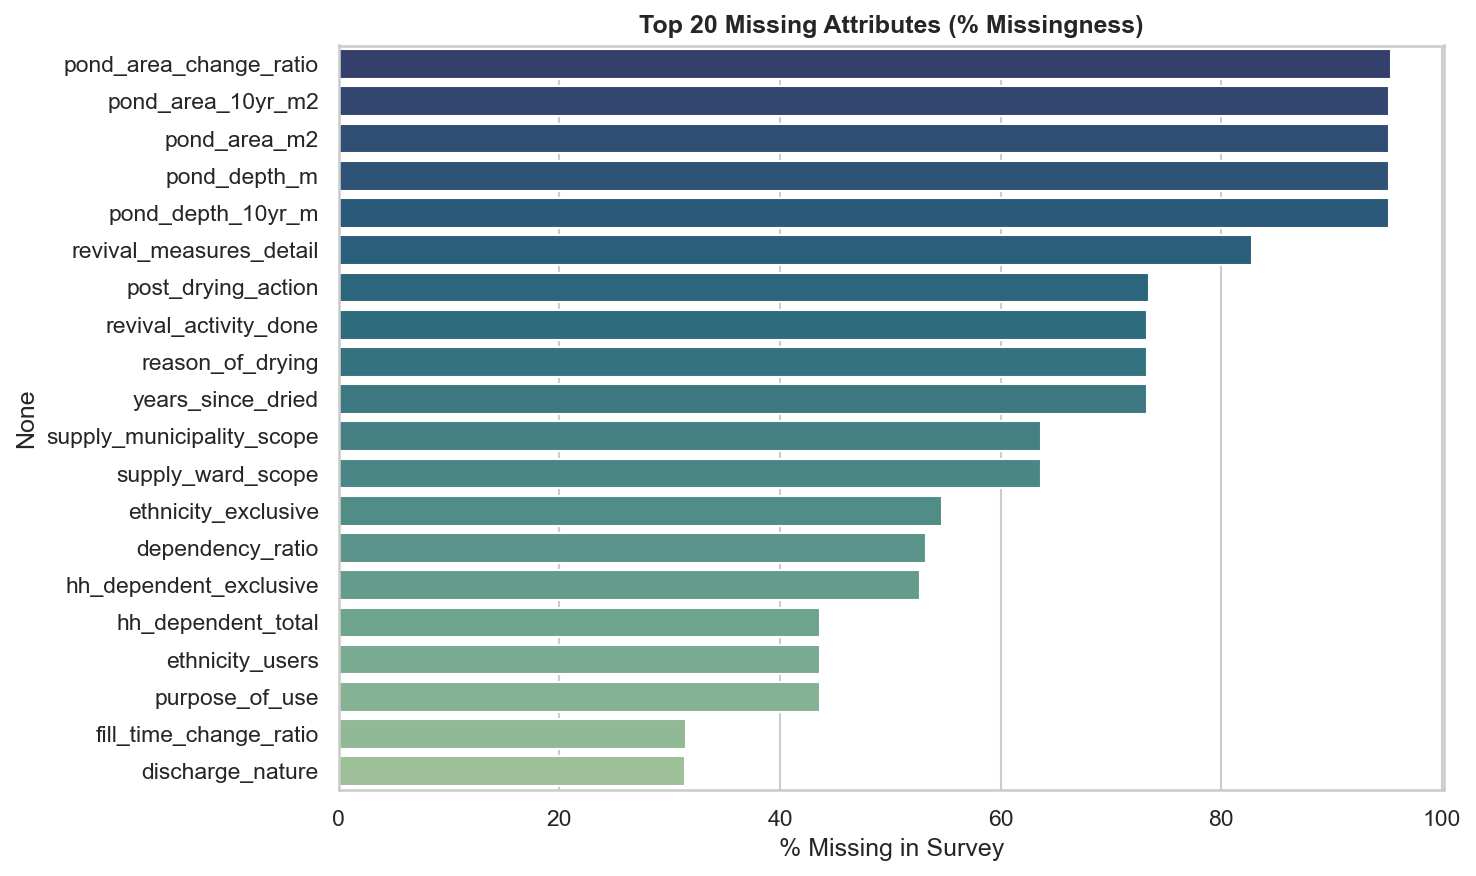

Attributes with ZERO missing values: 38


In [2]:
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_top = missing_pct[missing_pct > 0]

plt.figure(figsize=(10, 6))
sns.barplot(x=missing_top.head(20).values, y=missing_top.head(20).index, palette='crest_r')
plt.title('Top 20 Missing Attributes (% Missingness)', fontweight='bold')
plt.xlabel('% Missing in Survey')
plt.tight_layout()
plt.show()

print("Attributes with ZERO missing values:", len(missing_pct[missing_pct == 0]))

## 2. Primary Target Distribution: Active vs. Dried Sources
- `0`: Active spring/pond ($n = 4,168$)
- `1`: Dried spring/pond ($n = 1,521$, $26.7\%$)

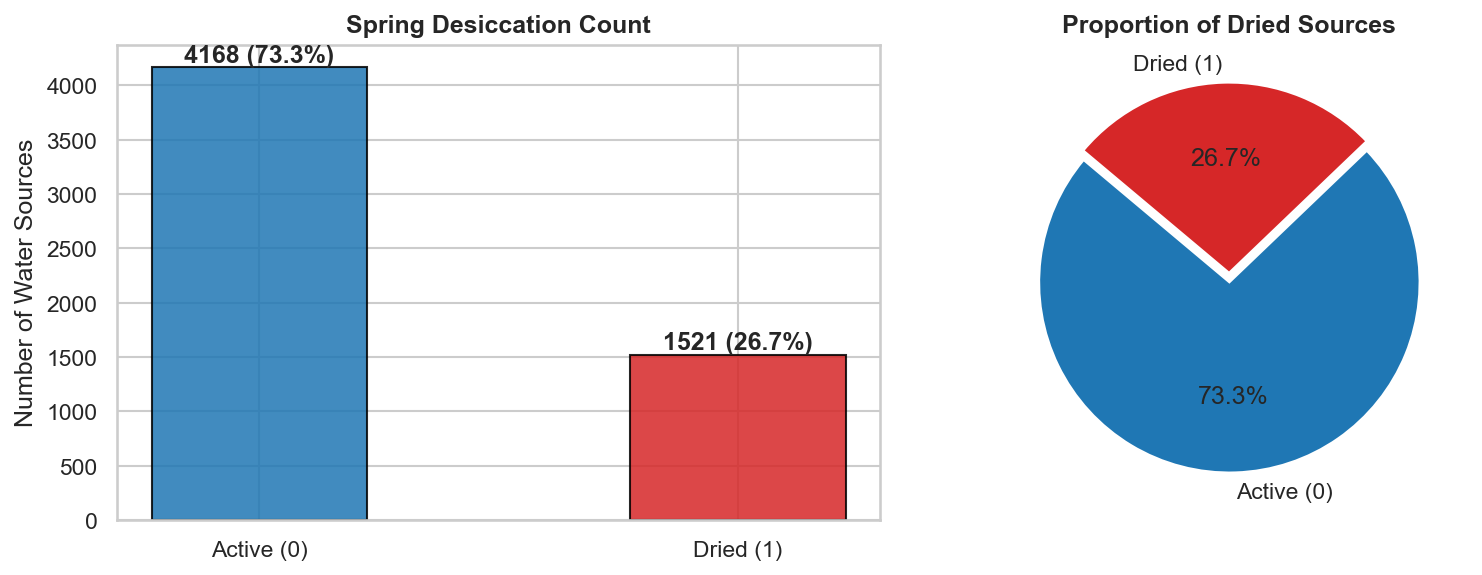

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = df['target_dried'].value_counts().sort_index()
labels = ['Active (0)', 'Dried (1)']
colors = ['#1f77b4', '#d62728']

ax[0].bar(labels, counts, color=colors, edgecolor='black', alpha=0.85, width=0.45)
ax[0].set_title('Spring Desiccation Count', fontweight='bold')
ax[0].set_ylabel('Number of Water Sources')
for i, v in enumerate(counts):
    ax[0].text(i, v + 50, f'{v} ({v/len(df)*100:.1f}%)', ha='center', fontweight='bold')

ax[1].pie(counts, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, explode=[0, 0.05])
ax[1].set_title('Proportion of Dried Sources', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Physical & Environmental Drivers of Desiccation
Cross-tabulating drying rates across **Source Type** (spring vs pond), **Seasonality** (perennial vs seasonal), and **Surrounding Land Use**.

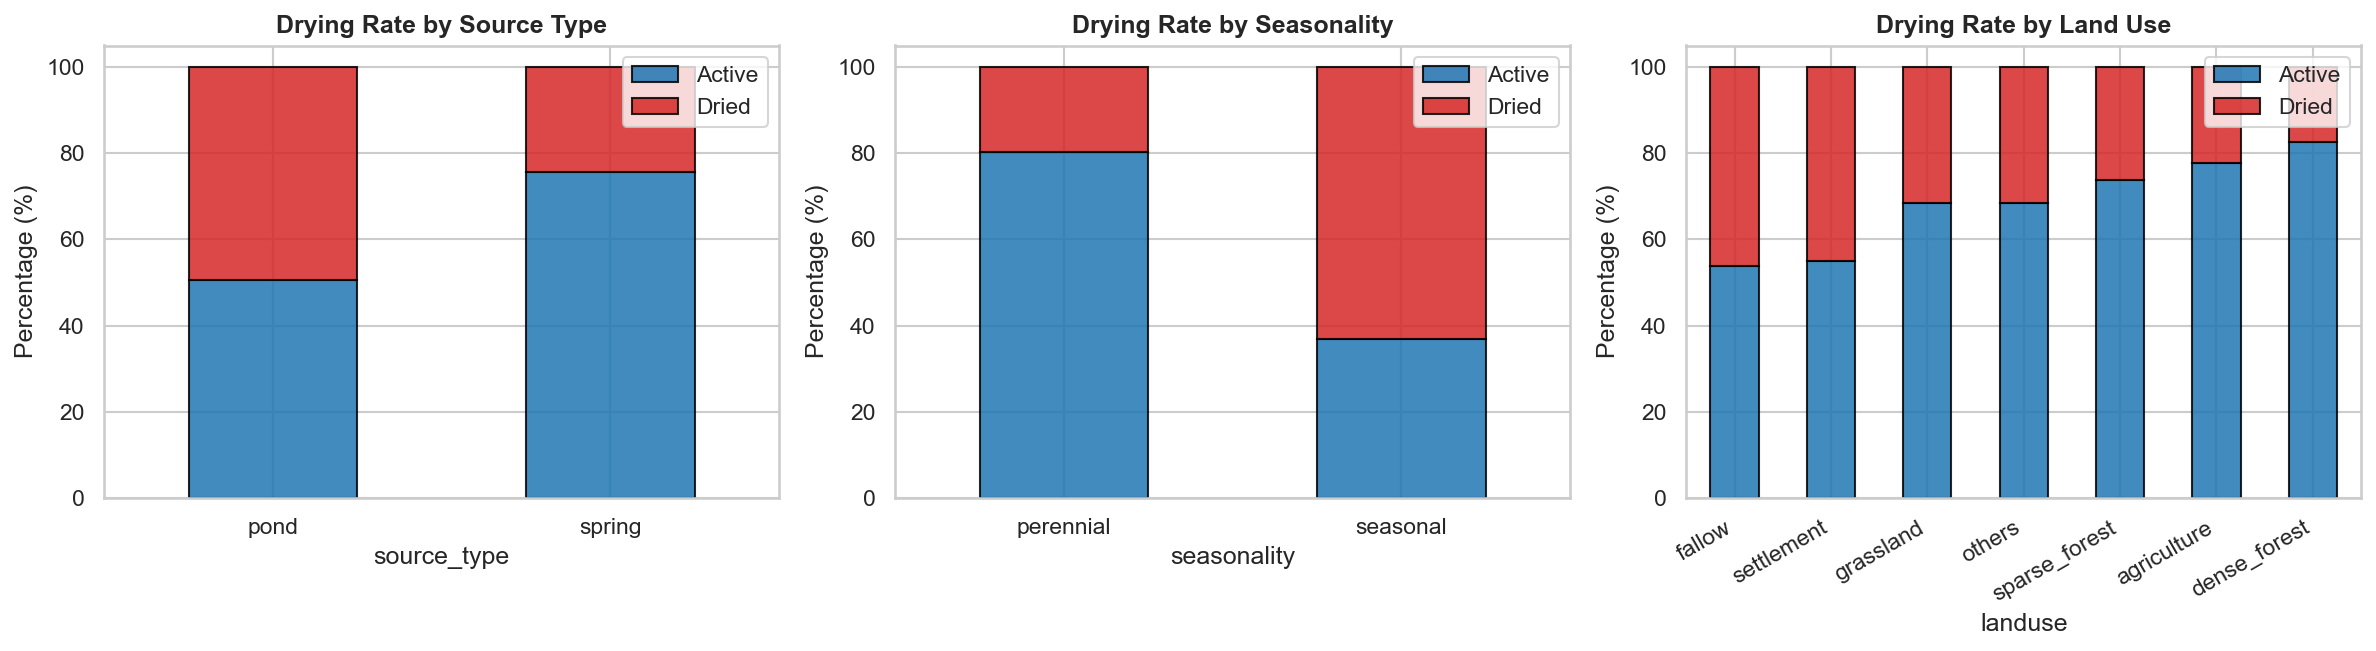

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# A. Source Type
ct_type = pd.crosstab(df['source_type'], df['target_dried'], normalize='index') * 100
ct_type.plot(kind='bar', stacked=True, ax=ax[0], color=['#1f77b4', '#d62728'], alpha=0.85, edgecolor='black')
ax[0].set_title('Drying Rate by Source Type', fontweight='bold')
ax[0].set_ylabel('Percentage (%)')
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=0)
ax[0].legend(['Active', 'Dried'], loc='upper right')

# B. Seasonality
ct_season = pd.crosstab(df['seasonality'], df['target_dried'], normalize='index') * 100
ct_season.plot(kind='bar', stacked=True, ax=ax[1], color=['#1f77b4', '#d62728'], alpha=0.85, edgecolor='black')
ax[1].set_title('Drying Rate by Seasonality', fontweight='bold')
ax[1].set_ylabel('Percentage (%)')
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=0)
ax[1].legend(['Active', 'Dried'], loc='upper right')

# C. Surrounding Land Use
lu_order = df.groupby('landuse')['target_dried'].mean().sort_values(ascending=False).index
ct_lu = pd.crosstab(df['landuse'], df['target_dried'], normalize='index').loc[lu_order] * 100
ct_lu.plot(kind='bar', stacked=True, ax=ax[2], color=['#1f77b4', '#d62728'], alpha=0.85, edgecolor='black')
ax[2].set_title('Drying Rate by Land Use', fontweight='bold')
ax[2].set_ylabel('Percentage (%)')
ax[2].set_xticklabels(ax[2].get_xticklabels(), rotation=30, ha='right')
ax[2].legend(['Active', 'Dried'], loc='upper right')

plt.tight_layout()
plt.show()

## 4. Disaster Vulnerability: 2015 Gorkha Earthquake Impact
Did the 2015 earthquake trigger spring extinction or flow changes?

> **Caveat — survey skip logic.** The questionnaire (Thapa et al., 2025, *Data in Brief* 60:111466) asks the earthquake-impact question only in sections that are **skipped for dried sources**: 1,513 of 1,521 dried sources have no answer, versus ~6 % of active sources. The cross-tab below therefore describes *active* springs only and says nothing about whether the earthquake caused drying. These fields must never be used as model features (see `src/features.py` and `results/metrics/leakage_audit.csv`).

Springs with documented 2015 earthquake observations: 3821
                   total  dried_count  drying_rate  drying_pct
earthquake_impact                                             
decreased            963            0          0.0         0.0
degraded             871            0          0.0         0.0
dried                 90            0          0.0         0.0
increased            138            0          0.0         0.0
no_change           1759            0          0.0         0.0


C:\Users\ACER\AppData\Local\Temp\ipykernel_20080\2792361792.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=eq_summary.index, y=eq_summary['drying_pct'], palette='rocket')


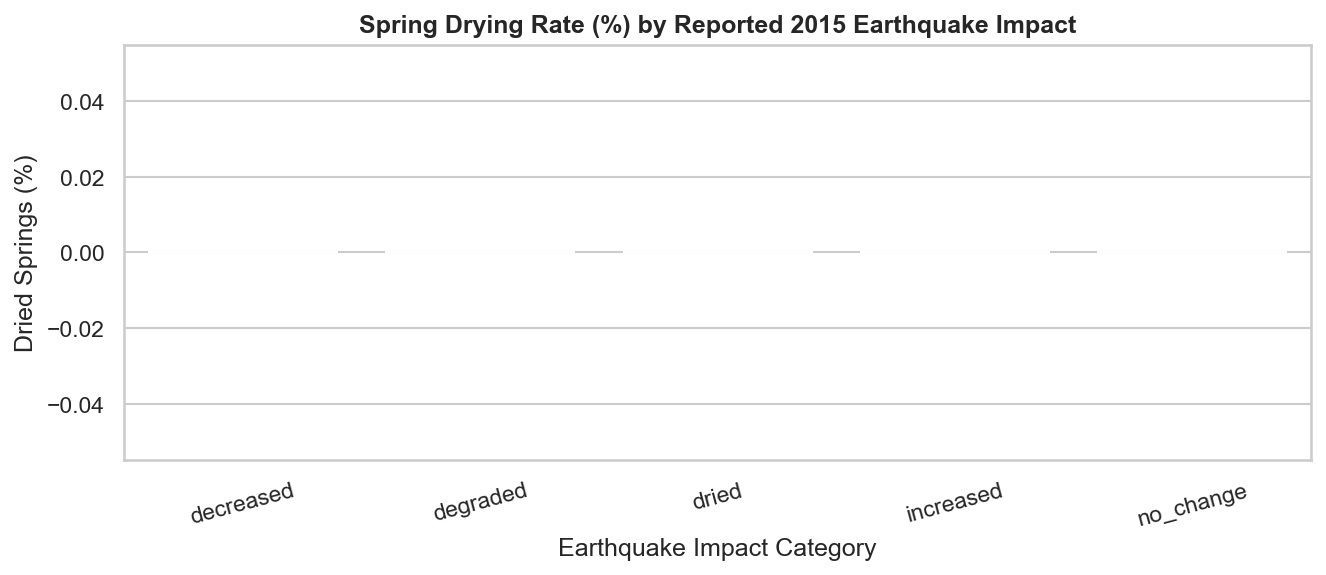

In [5]:
eq_known = df[df['earthquake_impact_known'] == 1]
print("Springs with documented 2015 earthquake observations:", len(eq_known))

eq_summary = eq_known.groupby('earthquake_impact').agg(
    total=('id', 'count'),
    dried_count=('target_dried', 'sum'),
    drying_rate=('target_dried', 'mean')
).sort_values('drying_rate', ascending=False)
eq_summary['drying_pct'] = (eq_summary['drying_rate'] * 100).round(1)
print(eq_summary)

plt.figure(figsize=(9, 4))
sns.barplot(x=eq_summary.index, y=eq_summary['drying_pct'], palette='rocket')
plt.title('Spring Drying Rate (%) by Reported 2015 Earthquake Impact', fontweight='bold')
plt.ylabel('Dried Springs (%)')
plt.xlabel('Earthquake Impact Category')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 5. Reasons for Drying (Surveyed Dried Springs)
For the 1,521 dried springs, what did the community cite as the primary drying cause?

C:\Users\ACER\AppData\Local\Temp\ipykernel_20080\1273063264.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=reason_counts.values, y=reason_counts.index, palette='copper')


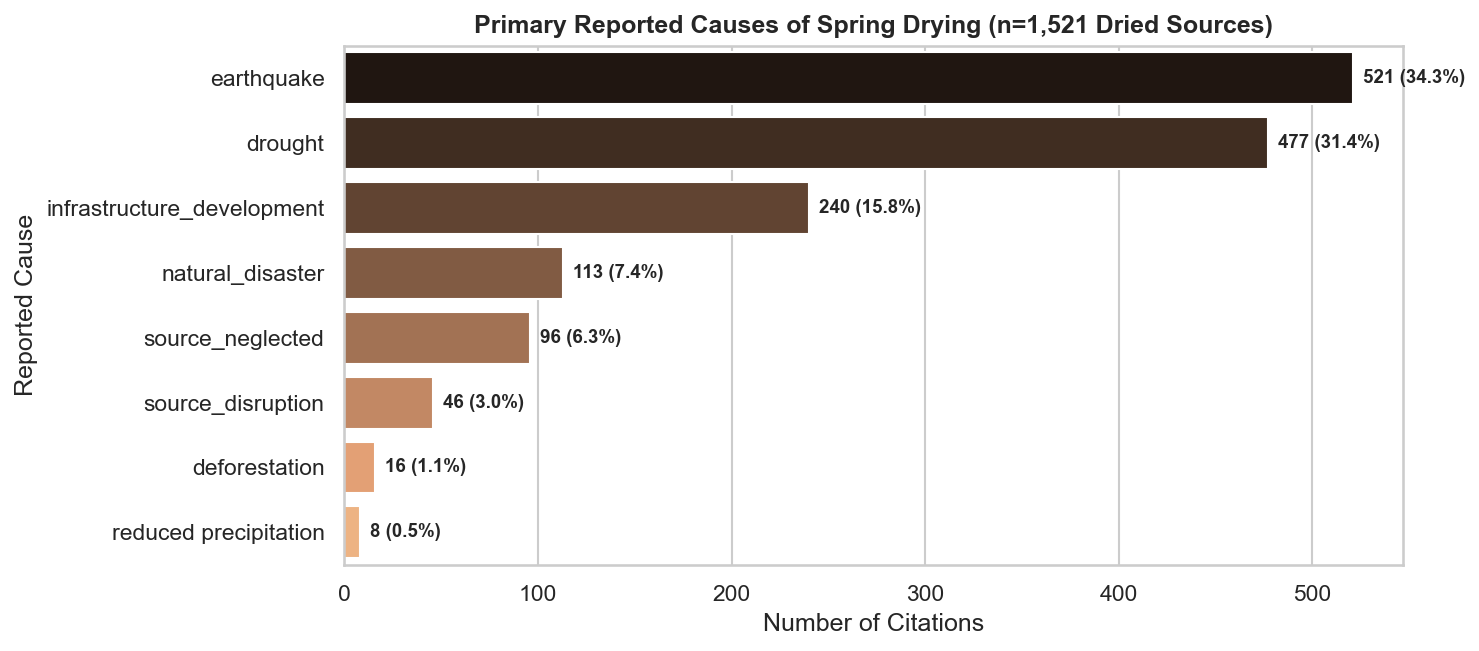

In [6]:
dried_df = df[df['target_dried'] == 1]
reason_counts = dried_df['reason_of_drying'].value_counts().head(8)

plt.figure(figsize=(10, 4.5))
sns.barplot(x=reason_counts.values, y=reason_counts.index, palette='copper')
plt.title('Primary Reported Causes of Spring Drying (n=1,521 Dried Sources)', fontweight='bold')
plt.xlabel('Number of Citations')
plt.ylabel('Reported Cause')
for i, v in enumerate(reason_counts.values):
    plt.text(v + 5, i, f'{v} ({v/len(dried_df)*100:.1f}%)', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Discharge Dynamics & Flow Rates (Active Springs)
Analyzing current bucket flow rate ($L/\text{min}$) and temporal 10-year discharge change ratio.

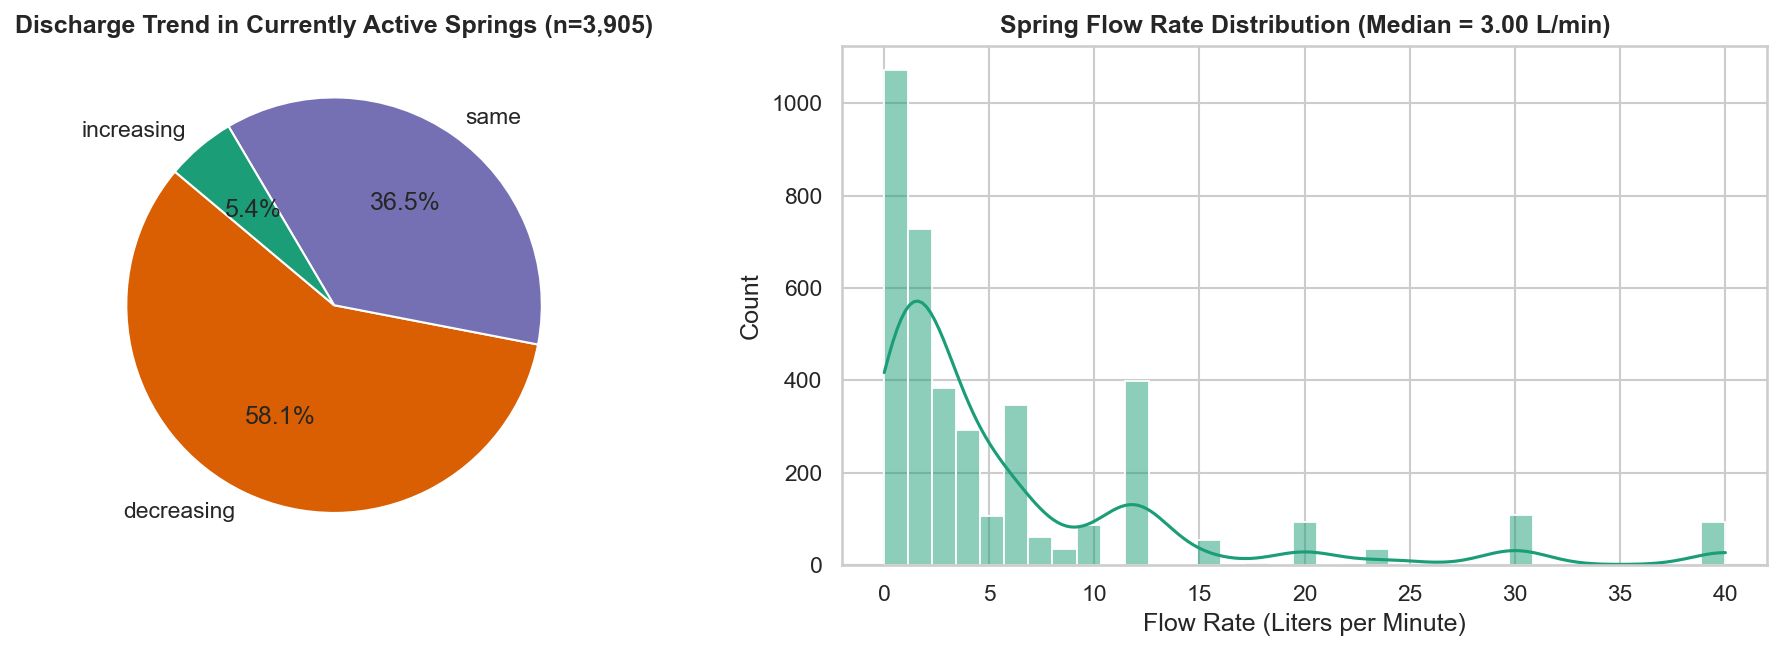

In [7]:
active_df = df[df['target_dried'] == 0]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# A. Trend breakdown
trend_counts = active_df['discharge_trend'].value_counts()
ax[0].pie(trend_counts, labels=trend_counts.index, autopct='%1.1f%%', colors=['#d95f02', '#7570b3', '#1b9e77'], startangle=140)
ax[0].set_title('Discharge Trend in Currently Active Springs (n=3,905)', fontweight='bold')

# B. Flow Rate distribution (clipped at 40 LPM for visualization)
flow = active_df['flow_rate_lpm'].dropna().clip(upper=40)
sns.histplot(flow, bins=35, kde=True, ax=ax[1], color='#1b9e77')
ax[1].set_title(f'Spring Flow Rate Distribution (Median = {active_df.flow_rate_lpm.median():.2f} L/min)', fontweight='bold')
ax[1].set_xlabel('Flow Rate (Liters per Minute)')

plt.tight_layout()
plt.show()

## 7. Socio-Demographic Dependency & Water Burden
Measuring dependent households and fetching times across Kavre communities.

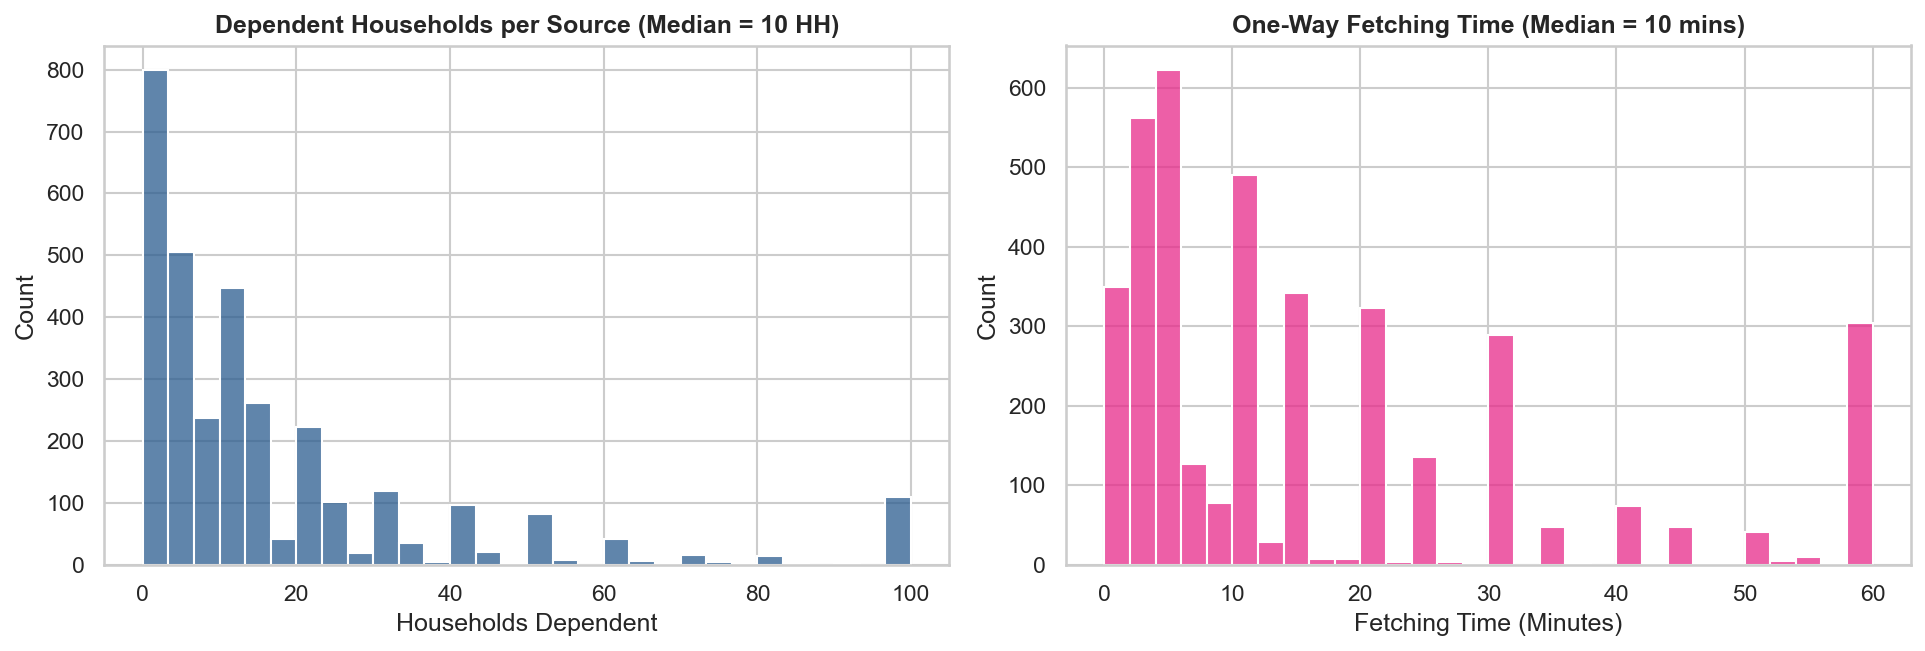

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# A. Household dependency
hh = df['hh_dependent_total'].dropna().clip(upper=100)
sns.histplot(hh, bins=30, ax=ax[0], color='#2b5c8f')
ax[0].set_title(f'Dependent Households per Source (Median = {df.hh_dependent_total.median():.0f} HH)', fontweight='bold')
ax[0].set_xlabel('Households Dependent')

# B. Fetching Time
fetch = df['fetch_time_minutes'].dropna().clip(upper=60)
sns.histplot(fetch, bins=30, ax=ax[1], color='#e7298a')
ax[1].set_title(f'One-Way Fetching Time (Median = {df.fetch_time_minutes.median():.0f} mins)', fontweight='bold')
ax[1].set_xlabel('Fetching Time (Minutes)')

plt.tight_layout()
plt.show()